# 1. Read source data

In [1]:
import sys
import numpy as np
import pandas as pd
PATH_TO_PREDICTOR_HOME = ".."
sys.path.append(PATH_TO_PREDICTOR_HOME)

In [2]:
from data_reading import read_gbm122_data

#DATA_PATH_SOURCE = "/home/denklewer/Data/gbm122/pVACseq/"
DATA_PATH_SOURCE = "D:/Google Drive/Work/ITMO/data/gbm122/pVACseq/"

per_region_total_df , per_region_per_allele_mt_df, per_region_per_allele_wt_df = read_gbm122_data(DATA_PATH_SOURCE)


Region 1, unique (Transcrpit, Epitope pairs): 13197
found 5 alleles: ['HLA-A*03:01' 'HLA-B*35:01' 'HLA-B*40:01' 'HLA-C*03:04' 'HLA-C*04:01']
allele HLA-A*03:01: initial length 13221
take unique (MT_epitope, WT_epitope) pairs
result length 5409
allele HLA-B*35:01: initial length 13221
take unique (MT_epitope, WT_epitope) pairs
result length 5409
allele HLA-B*40:01: initial length 13221
take unique (MT_epitope, WT_epitope) pairs
result length 5409
allele HLA-C*03:04: initial length 13221
take unique (MT_epitope, WT_epitope) pairs
result length 5409
allele HLA-C*04:01: initial length 13221
take unique (MT_epitope, WT_epitope) pairs
result length 5409
Region 2, unique (Transcrpit, Epitope pairs): 13273
found 5 alleles: ['HLA-A*03:01' 'HLA-B*35:01' 'HLA-B*40:01' 'HLA-C*03:04' 'HLA-C*04:01']
allele HLA-A*03:01: initial length 13279
take unique (MT_epitope, WT_epitope) pairs
result length 5127
allele HLA-B*35:01: initial length 13279
take unique (MT_epitope, WT_epitope) pairs
result length 51

D:\Tools\Python\Anaconda\envs\tf_env\lib\site-packages\IPython\core\interactiveshell.py:3347: DtypeWarning: Columns (10) have mixed types.Specify dtype option on import or set low_memory=False.
  if (await self.run_code(code, result,  async_=asy)):


Region 3, unique (Transcrpit, Epitope pairs): 15170
found 5 alleles: ['HLA-A*03:01' 'HLA-B*35:01' 'HLA-B*40:01' 'HLA-C*03:04' 'HLA-C*04:01']
allele HLA-A*03:01: initial length 15170
take unique (MT_epitope, WT_epitope) pairs
result length 4971
allele HLA-B*35:01: initial length 15170
take unique (MT_epitope, WT_epitope) pairs
result length 4971
allele HLA-B*40:01: initial length 15170
take unique (MT_epitope, WT_epitope) pairs
result length 4971
allele HLA-C*03:04: initial length 15170
take unique (MT_epitope, WT_epitope) pairs
result length 4971
allele HLA-C*04:01: initial length 15170
take unique (MT_epitope, WT_epitope) pairs
result length 4971
Region 4, unique (Transcrpit, Epitope pairs): 13757
found 5 alleles: ['HLA-A*03:01' 'HLA-B*35:01' 'HLA-B*40:01' 'HLA-C*03:04' 'HLA-C*04:01']
allele HLA-A*03:01: initial length 13757
take unique (MT_epitope, WT_epitope) pairs
result length 4932
allele HLA-B*35:01: initial length 13757
take unique (MT_epitope, WT_epitope) pairs
result length 49

# 2. Check if we have all the regions and alleles

In [3]:
sample_region_dict = next(iter(per_region_per_allele_wt_df.values()))
sample_allele_df =  next(iter(sample_region_dict.values()))

ALLELES = list(sample_region_dict.keys())
REGIONS = list(per_region_total_df.keys())
ALLELES, REGIONS

(['HLA-A*03:01', 'HLA-B*35:01', 'HLA-B*40:01', 'HLA-C*03:04', 'HLA-C*04:01'],
 [1, 2, 3, 4, 5])

# 3. Read Top epitopes (My)

In [11]:
COMBINATIONS = ['_all_regions_netMHCpan-4.1',
                '_all_regions_mhcnuggets_acme_puffin', 
                '_all_regions_netMHCpan-4.1_mhcnuggets_acme_puffin',
                '_all_regions_netMHCpan-4.1_mhcnuggets_acme_puffin_mhcseqnet',
                '+advantage_all_regions_mhcnuggets_acme_puffin',
                '+advantage_all_regions_netMHCpan-4.1_mhcnuggets_acme_puffin',
                '+advantage_all_regions_netMHCpan-4.1_mhcnuggets_acme_puffin_mhcseqnet',
                '+advantage_all_regions_netMHCpan-4.1'
               ]
DATA_PATH = "D:/Google Drive/Work/ITMO/MHC-Epitop-Prediction/prediction_results/gbm122/" # windows

per_combination_df = dict()
for combination in COMBINATIONS:
    combination_df = pd.read_csv("{}top_epitopes_filtered{}.csv".format(DATA_PATH,combination),sep=";")
    per_combination_df[combination] = combination_df

#df_filtered.to_csv("{}top_epitopes_filtered+advantage_all_regions_{}.csv".format(DATA_PATH, "_".join(selected_methods)),sep=";", index=False)
combination_df

,region,allele,peptide_mt,peptide_wt,netMHC-3.4_score_mt,netMHC-3.4_affinity_mt,netMHC-4.0_score_mt,netMHC-4.0_affinity_mt,netMHC-4.0_percentile_rank_mt,netMHCpan-4.1_score_ba_mt,...,Normal VAF,Gene Expression,cterm_7mer_gravy_score,max_7mer_gravy_score,difficult_n_terminal_residue,c_terminal_cysteine,c_terminal_proline,cysteine_count,n_terminal_asparagine,asparagine_proline_bond_count
0,Region_1,HLA-A*03:01,KIRDSARQK,KIRDSAGQK,0.563,113.0,0.530,161.03,0.60,0.615295,...,NaN,6.933,-2.700000,-1.500000,False,False,False,0,False,0
1,Region_1,HLA-A*03:01,SLNNTWLNR,SLDNTWLNR,0.526,169.0,0.527,166.96,0.70,0.499222,...,NaN,6.904,-1.828571,-0.257143,False,False,False,0,False,0
2,Region_1,HLA-A*03:01,SLGWIRTRR,SLGRIRTRR,0.378,832.0,0.393,712.64,1.60,0.388432,...,NaN,11.069,-1.571429,0.142857,False,False,False,0,False,0
3,Region_1,HLA-A*03:01,MVHLGVVLY,MGHLGVVLY,0.455,362.0,0.382,800.29,1.70,0.371971,...,NaN,25.663,1.585714,2.371429,False,False,False,0,False,0
4,Region_1,HLA-A*03:01,SARQKGTGK,SAGQKGTGK,0.253,3247.0,0.338,1290.05,2.50,0.330274,...,NaN,6.933,-2.471429,-1.657143,False,False,False,0,False,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
314,Region_5,HLA-C*04:01,YMEKHLLEA,YMGKHLLEA,0.056,27399.0,0.100,16889.12,8.00,0.155148,...,NaN,5.353,-0.671429,-0.342857,False,False,False,0,False,0
315,Region_5,HLA-C*04:01,LWEPGWERL,PWEPGWERL,0.274,2587.0,0.230,4160.55,0.25,0.258478,...,NaN,7.335,-1.514286,-1.000000,False,False,False,0,False,0
316,Region_5,HLA-C*04:01,AVDITQEEW,AVDITQEDW,0.045,30790.0,0.064,24991.61,17.00,0.066555,...,NaN,2.784,-1.585714,-0.100000,False,False,False,0,False,0
317,Region_5,HLA-C*04:01,SYKELHGTL,SYKELRGTL,0.169,8057.0,0.177,7372.81,1.10,0.113079,...,NaN,9.017,-0.585714,-0.585714,False,False,False,0,False,0


# 4. Read Top epitopes (by other team)

In [12]:
other_df = pd.read_csv("{}(source)Top_epitopes_filtered_all_regions.csv".format(DATA_PATH),sep=";")
other_df

,Region,Chromosome,Start,Stop,Reference,Variant,Transcript,Ensembl Gene ID,Variant Type,Mutation,...,NetMHCpan WT Score,NetMHCpan MT Score,cterm_7mer_gravy_score,max_7mer_gravy_score,difficult_n_terminal_residue,c_terminal_cysteine,c_terminal_proline,cysteine_count,n_terminal_asparagine,asparagine_proline_bond_count
0,Region_1,chr5,112839770,112839771,C,G,ENST00000257430,ENSG00000134982,missense,L/V,...,"510,3","348,2","0,757142857","0,757142857",ЛОЖЬ,ЛОЖЬ,ЛОЖЬ,0,ЛОЖЬ,0
1,Region_2,chr5,112839770,112839771,C,G,ENST00000257430,ENSG00000134982,missense,L/V,...,"510,3","348,2","0,757142857","0,757142857",ЛОЖЬ,ЛОЖЬ,ЛОЖЬ,0,ЛОЖЬ,0
2,Region_4,chr5,112839770,112839771,C,G,ENST00000257430,ENSG00000134982,missense,L/V,...,"510,3","348,2","0,757142857","0,757142857",ЛОЖЬ,ЛОЖЬ,ЛОЖЬ,0,ЛОЖЬ,0
3,Region_5,chr5,112839770,112839771,C,G,ENST00000257430,ENSG00000134982,missense,L/V,...,"510,3","348,2","0,757142857","0,757142857",ЛОЖЬ,ЛОЖЬ,ЛОЖЬ,0,ЛОЖЬ,0
4,Region_1,chr12,6594564,6594565,C,A,ENST00000357008,ENSG00000111642,missense,W/L,...,"46,1",17,"0,842857143","0,842857143",ЛОЖЬ,ЛОЖЬ,ЛОЖЬ,0,ЛОЖЬ,0
5,Region_2,chr12,6594564,6594565,C,A,ENST00000357008,ENSG00000111642,missense,W/L,...,"46,1",17,"0,842857143","0,842857143",ЛОЖЬ,ЛОЖЬ,ЛОЖЬ,0,ЛОЖЬ,0
6,Region_1,chr1,43971559,43971560,G,T,ENST00000255108,ENSG00000132768,missense,G/W,...,"229,1","139,9","-0,042857143","0,828571429",ЛОЖЬ,ЛОЖЬ,ЛОЖЬ,0,ЛОЖЬ,0
7,Region_5,chr1,43971559,43971560,G,T,ENST00000255108,ENSG00000132768,missense,G/W,...,"229,1","139,9","-0,042857143","0,828571429",ЛОЖЬ,ЛОЖЬ,ЛОЖЬ,0,ЛОЖЬ,0
8,Region_4,chr1,241872189,241872190,C,A,ENST00000348581,ENSG00000174371,missense,P/T,...,"1005,4","281,6","-2,771428571","-1,928571429",ЛОЖЬ,ЛОЖЬ,ЛОЖЬ,0,ЛОЖЬ,0
9,Region_4,chr12,13753624,13753625,C,G,ENST00000609686,ENSG00000273079,missense,K/N,...,"312,2",264,"-1,628571429","-1,085714286",ЛОЖЬ,ЛОЖЬ,ЛОЖЬ,1,ЛОЖЬ,0


In [13]:
per_combination_my_peptides = {combination : combination_df['peptide_mt'].values for combination, combination_df in per_combination_df.items()}
per_combination_other_peptides = {combination : other_df['MT Epitope Seq'].values for combination in per_combination_df.keys()}

In [14]:

len(set(per_combination_my_peptides[combination])) , len(set(per_combination_other_peptides[combination]))

(79, 16)

In [15]:
PATH_TO_VISUALIZER_PROJECT = "D:/Google Drive/Work/ITMO/MHC-Epitop-Prediction/"
sys.path.append(PATH_TO_VISUALIZER_PROJECT)


from RNN_MHC_predictor.Visualizers.DataVisualizer import venn_intersection, per_suffix_venn_intersection


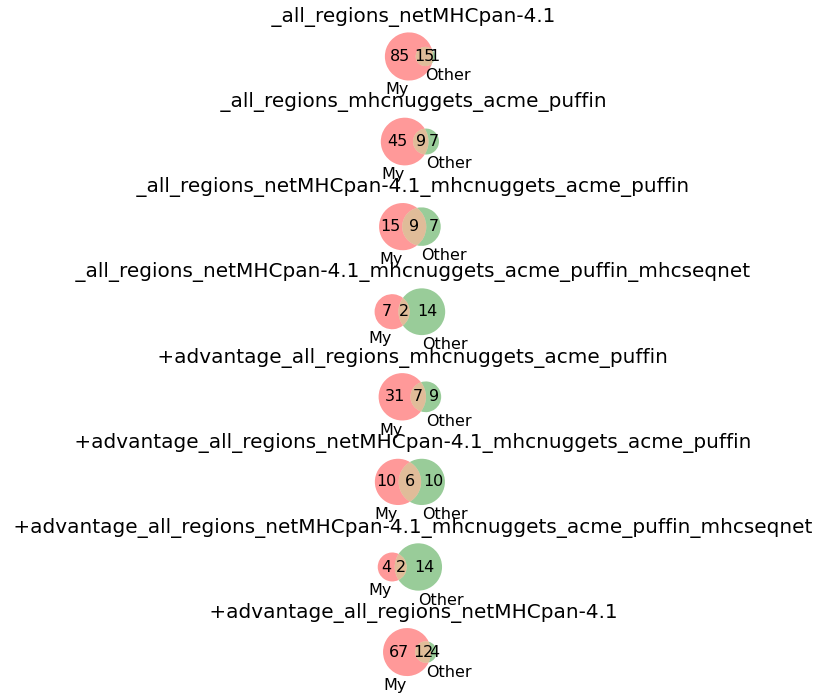

In [16]:
fig = per_suffix_venn_intersection([per_combination_my_peptides, per_combination_other_peptides], 
                             labels=["My", "Other"],
                             suffixes=COMBINATIONS,
                             base_title = "")

In [105]:
my_set = set(per_combination_my_peptides['+advantage_all_regions_netMHCpan-4.1_mhcnuggets_acme_puffin'])

In [106]:
other_set = set(per_combination_other_peptides['_all_regions_netMHCpan-4.1_mhcnuggets_acme_puffin'])

my_set.intersection(other_set)

{'MEKHLLEAF',
 'MPNEFSAQTF',
 'MVHLGVVLY',
 'SLNNTWLNR',
 'VVNFRRGFRK',
 'YQMEGLNLL'}

In [107]:
print("\n".join(my_set.intersection(other_set)))

VVNFRRGFRK
MVHLGVVLY
YQMEGLNLL
SLNNTWLNR
MEKHLLEAF
MPNEFSAQTF


In [108]:
print("\n".join(my_set))

MEKHLLEAF
VVNFRRGFRK
MVHLGVVLY
QEEKLMVHL
HEYEVTCAA
FEYKECGKSF
VEAQLPPQGL
YQMEGLNLL
SLNNTWLNR
MPNEFSAQT
MPNEFSAQTFY
MEVKPIMTTKL
HEYEVTCAAV
MPNEFSAQTF
KLFEYKECGK
MVHLGVVLYEY


# Per region per allele Venn

In [93]:
my_df_to_compare = per_combination_df['_all_regions_netMHCpan-4.1_mhcnuggets_acme_puffin']


per_region_per_allele_other_df = dict()
per_region_per_allele_my_df = dict()
per_region_my_peptides = {region: set() for region in REGIONS}
per_allele_my_peptides = {allele_name: set() for allele_name in ALLELES}

per_region_other_peptides = {region: set() for region in REGIONS}
per_allele_other_peptides = {allele_name: set() for allele_name in ALLELES}

for region in REGIONS:
    per_region_per_allele_other_df[region] = dict()
    per_region_per_allele_my_df[region] = dict()

    
    for allele_name in ALLELES:
        other_df_filtered = other_df[(other_df['Region'] == f"Region_{region}") & (other_df['HLA Allele'] == allele_name)].copy()
        my_df_to_compare_filtered = my_df_to_compare[(my_df_to_compare['region'] == f"Region_{region}") & (my_df_to_compare['allele'] == allele_name)].copy()
        per_region_per_allele_other_df[region][allele_name] = other_df_filtered
        per_region_per_allele_my_df[region][allele_name] = my_df_to_compare_filtered
        per_region_my_peptides[region].update(my_df_to_compare_filtered['peptide_mt'].values)
        per_allele_my_peptides[allele_name].update(my_df_to_compare_filtered['peptide_mt'].values)
        
        per_region_other_peptides[region].update(other_df_filtered['MT Epitope Seq'].values)
        per_allele_other_peptides[allele_name].update(other_df_filtered['MT Epitope Seq'].values)
        

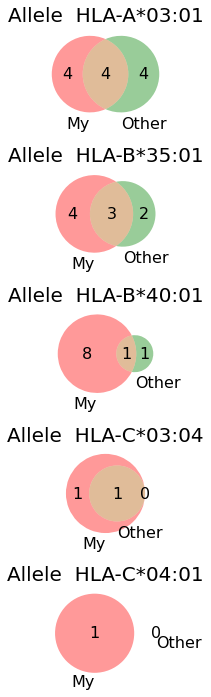

In [94]:
   
fig = per_suffix_venn_intersection([per_allele_my_peptides, per_allele_other_peptides], 
                     labels=["My", "Other"],
                     suffixes=ALLELES,
                     base_title = f"Allele ")
    

Region 1
Region 2
Region 3


D:\Tools\Python\Anaconda\envs\tf_env\lib\site-packages\matplotlib_venn\_venn2.py:50: UserWarning: Both circles have zero area
  warnings.warn("Both circles have zero area")


Region 4
Region 5


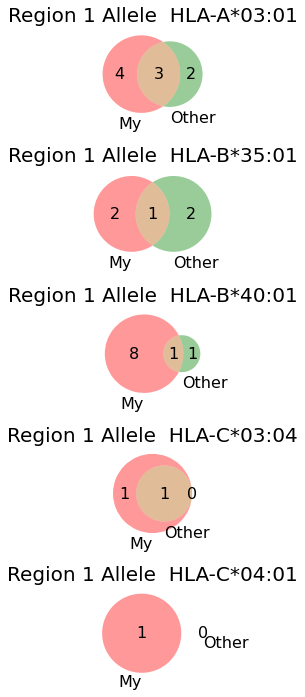

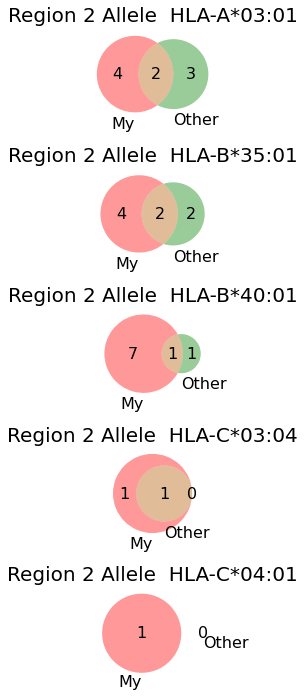

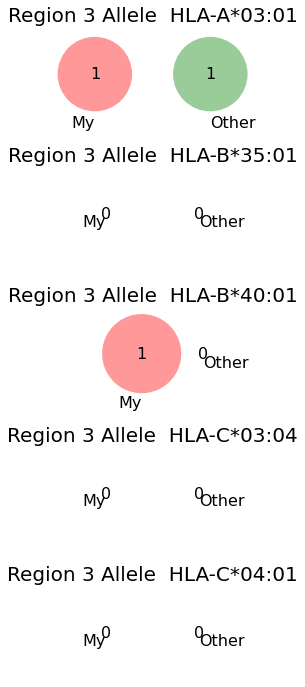

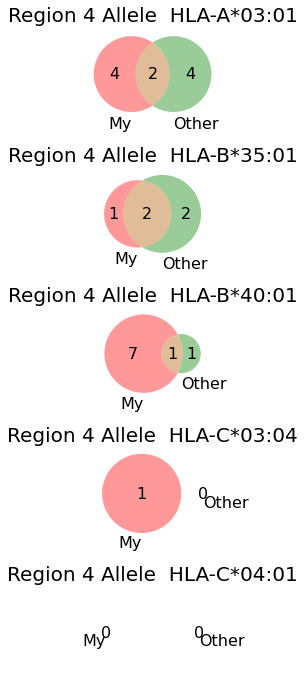

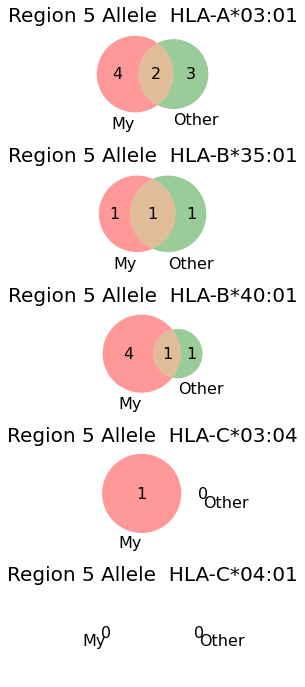

In [19]:
for region in REGIONS:
    print(f"Region {region}")
    per_allele_other_peptides = {allele_name: other_df['MT Epitope Seq'].values for allele_name,other_df in per_region_per_allele_other_df[region].items()}
    per_allele_my_peptides = {allele_name: my_df['peptide_mt'].values for allele_name,my_df in per_region_per_allele_my_df[region].items()}
    
    fig = per_suffix_venn_intersection([per_allele_my_peptides, per_allele_other_peptides], 
                         labels=["My", "Other"],
                         suffixes=ALLELES,
                         base_title = f"Region {region} Allele ")
        



# 3. Analythe peptides. Draw motifs

In [14]:
import logomaker

In [15]:
import numpy as np
from collections import defaultdict
import pandas as pd

import matplotlib.pyplot as plt

In [16]:
def get_motif_parameters_for_length(sequences, target_length = 8):
    target_length = target_length + 1 # Z symbol
    sequences = [x for x in sequences if len(x) == target_length]
    print("Total sequences for processing", len(sequences))
    d = defaultdict(lambda: [0]*target_length)  # d[char] = [pos0, pos12, ...]
    for seq in sequences:
        for i, char in enumerate(seq): 
            d[char][i] += 1
    count_df = pd.DataFrame(columns=list(amino_acids))


    for char in count_df.columns:
        count_df[char] = list(map(float,d[char]))[:-1]
    prob_matrix = logomaker.transform_matrix(count_df, from_type='counts', to_type='probability')
    information_matrix = logomaker.transform_matrix(count_df, from_type='counts', to_type='information')
    number = len(sequences)
    return count_df, prob_matrix, information_matrix, number

In [17]:
def plot_logo(information_matrix, ax, logo_params, text):
    curr_logo = logomaker.Logo(information_matrix, ax=ax , **logo_params)
    curr_logo.ax.set_title(f"{text}", fontsize=14, color="blue")
    curr_logo.ax.set_xticks(range(len(information_matrix)))
    return curr_logo

In [18]:
def plot_all_the_logos(information_matrices, lengths):
    plot_num = len(information_matrices)
    if plot_num > 0:
        fig, axes = plt.subplots(ncols=1, nrows=plot_num, figsize=(15, plot_num*5))
        logo_parameters = { 'font_name': 'Arial Rounded MT Bold',
    #                          'color_scheme': 'NajafabadiEtAl2017',
                           'vpad': 0.1,
    #                          'width': .8
                  }
        i = 0
        for title, matrix in information_matrices.items():
            if hasattr(axes, '__getitem__'):
                cur_logo = plot_logo(information_matrix=matrix, ax=axes[i], logo_params=logo_parameters, text=title + " Cnt " +  str(lengths[title]))
                i += 1
            else:
                cur_logo = plot_logo(information_matrix=matrix, ax=axes, logo_params=logo_parameters, text=title + " Cnt " +  str(lengths[title]))




        plt.subplots_adjust(hspace=0.35)
        return fig
    return None

In [19]:
LENGTHS_FOR_ANALYSIS = [8,9]
amino_acids = 'ACDEFGHIKLMNPQRSTVWY'

Total sequences for processing 15
Total sequences for processing 7
Total sequences for processing 8
Total sequences for processing 14
Total sequences for processing 8
Total sequences for processing 1
Total sequences for processing 12
Total sequences for processing 1
Total sequences for processing 15
Total sequences for processing 12
Total sequences for processing 4
Total sequences for processing 4
Total sequences for processing 6
Total sequences for processing 0
Total sequences for processing 2
Total sequences for processing 0
Total sequences for processing 2
Total sequences for processing 0
Total sequences for processing 0
Total sequences for processing 0


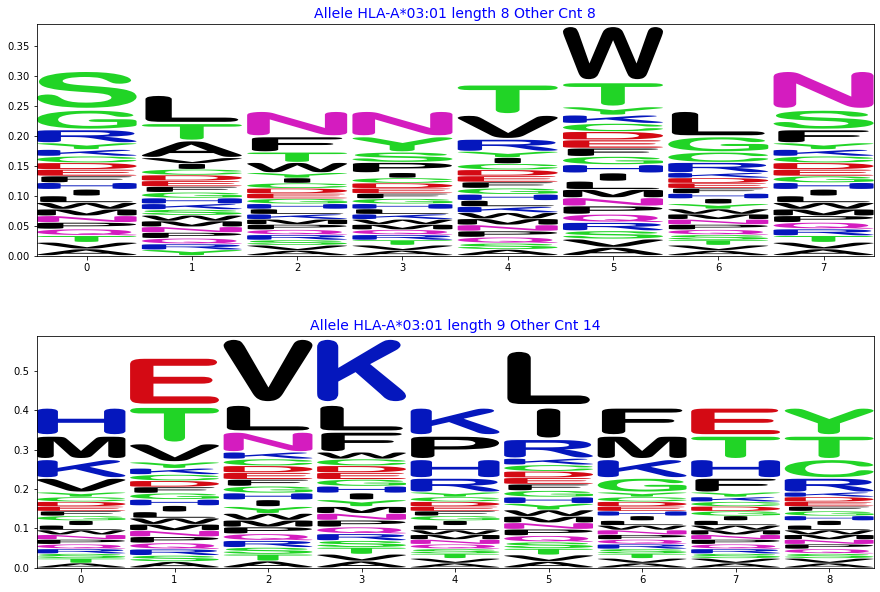

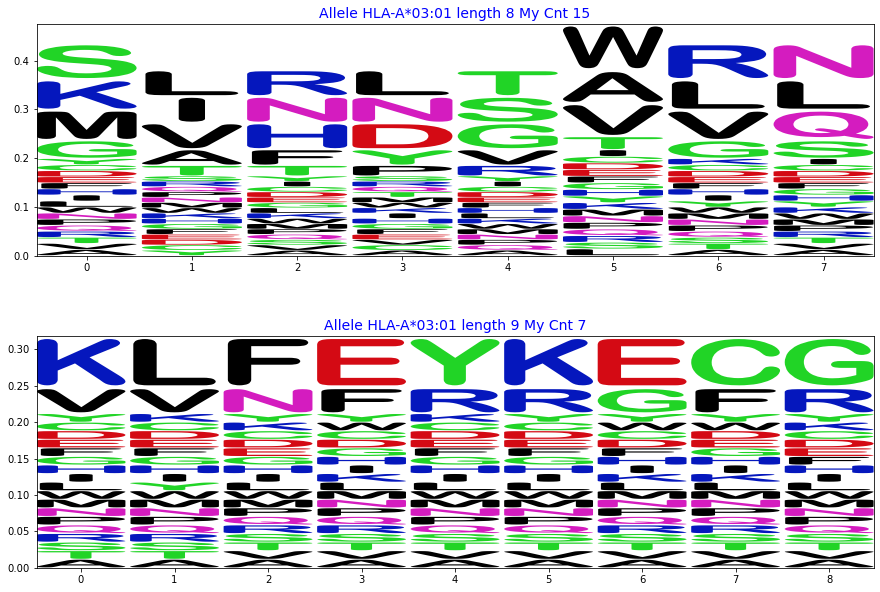

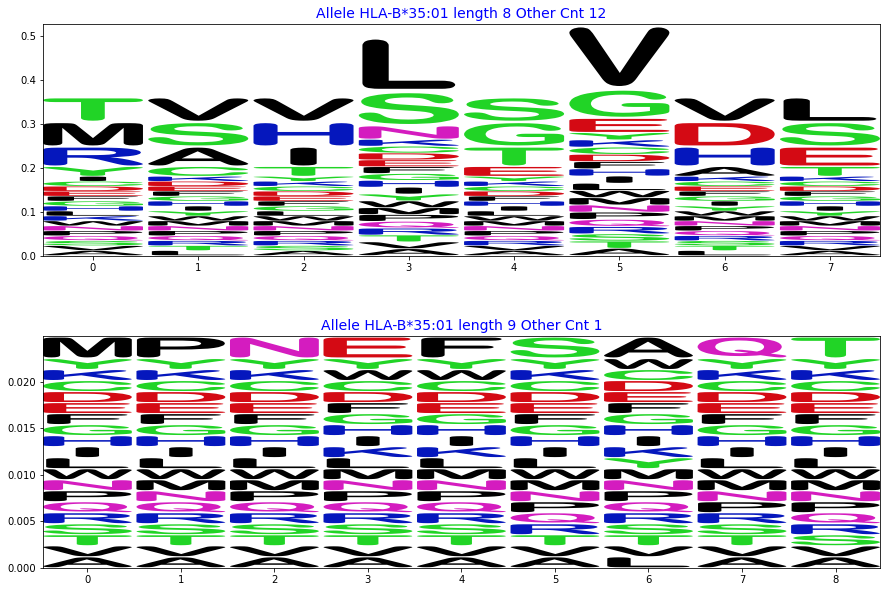

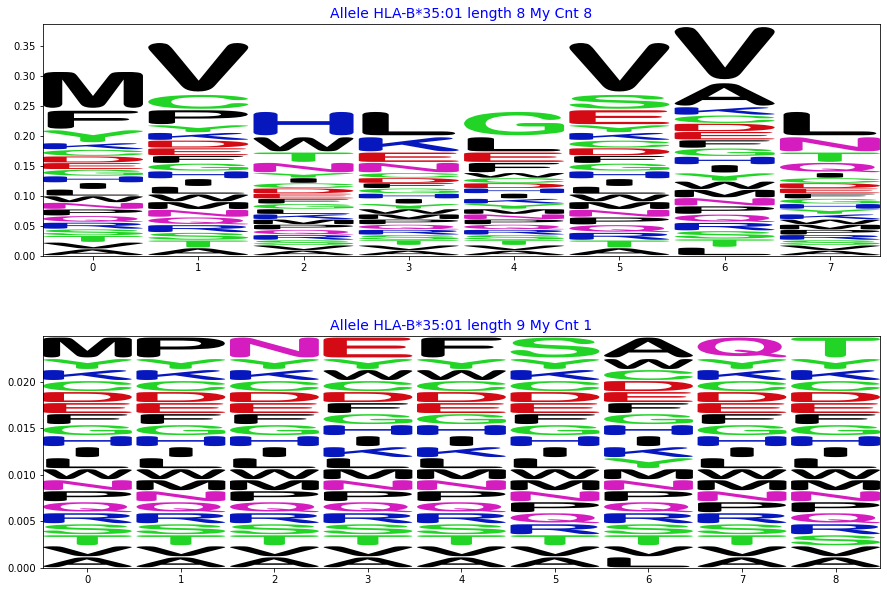

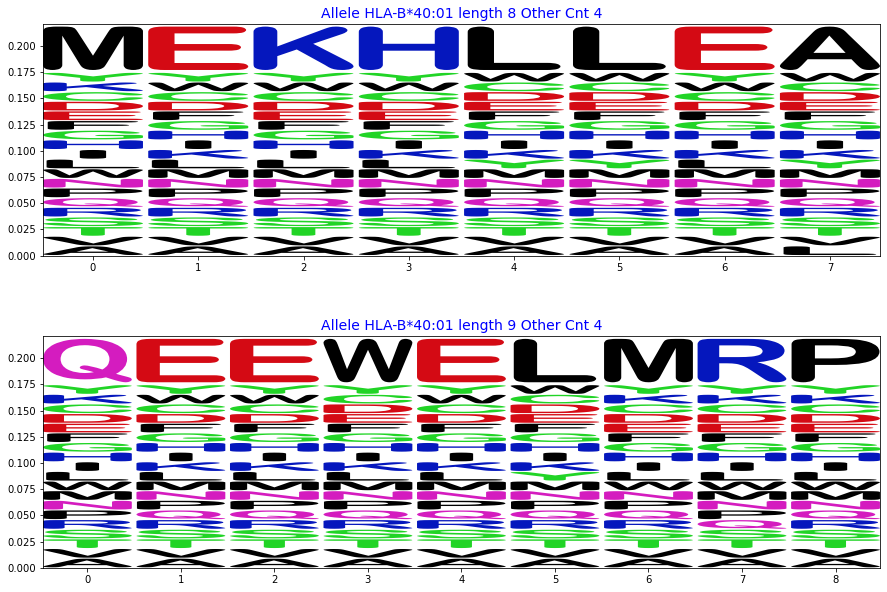

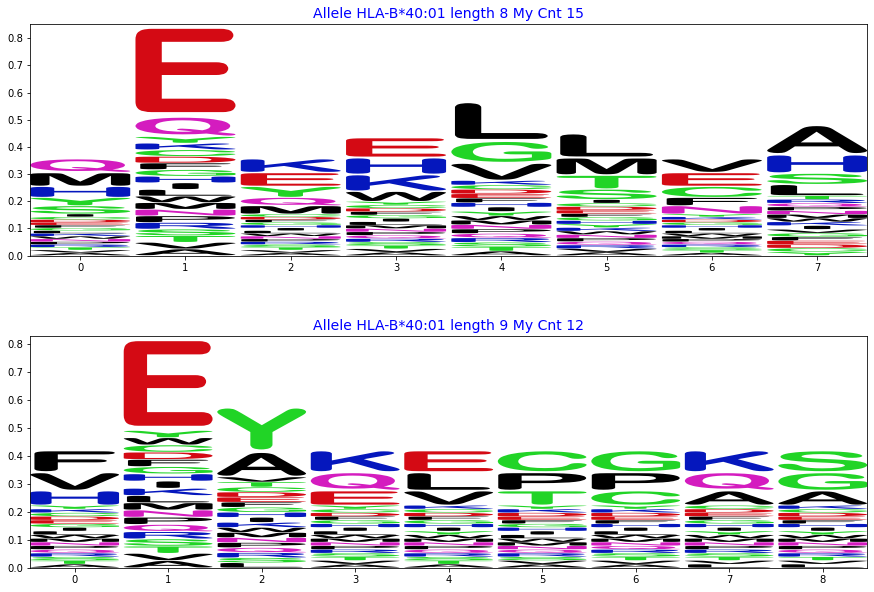

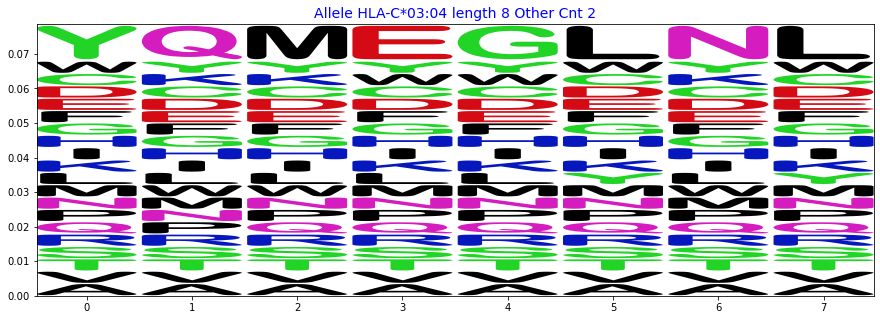

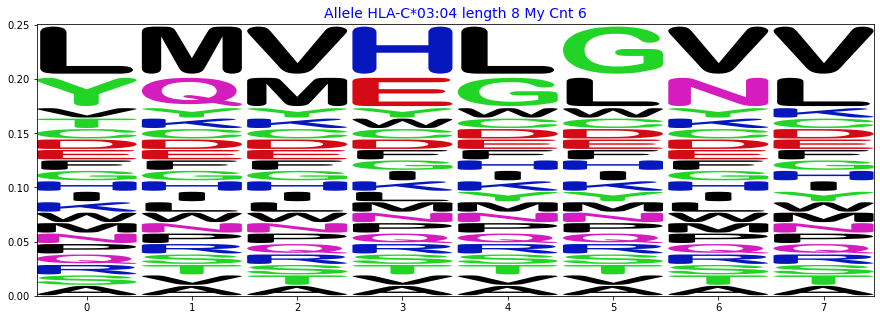

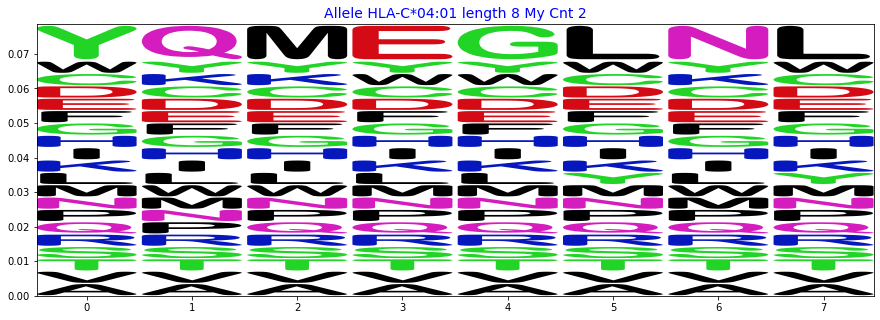

In [24]:
for allele_name in ALLELES:
    allele_df_list_other = [ other_df_dict[allele_name]['MT Epitope Seq'].values for region,other_df_dict in per_region_per_allele_other_df.items()]
    allele_df_list_my = [ my_df_dict[allele_name]['peptide_mt'].values for region, my_df_dict in per_region_per_allele_my_df.items()]


    other_peptides = np.concatenate(allele_df_list_other)
    my_peptides = np.concatenate(allele_df_list_my)
    
    information_matrices_my = dict()
    lengths_my = dict()
    for target_length in LENGTHS_FOR_ANALYSIS:
        count_df, real_prob_matrix, real_information_matrix,number = get_motif_parameters_for_length(my_peptides, target_length)
        if not number == 0:
            information_matrices_my[f"Allele {allele_name} length {target_length} My"] = real_information_matrix
            lengths_my[f"Allele {allele_name} length {target_length} My"] = number
        
    information_matrices_other = dict()
    lengths_other = dict()
    for target_length in LENGTHS_FOR_ANALYSIS:
        count_df, real_prob_matrix, real_information_matrix,number = get_motif_parameters_for_length(other_peptides, target_length)
        if not number == 0:
            information_matrices_other[f"Allele {allele_name} length {target_length} Other"] = real_information_matrix
            lengths_other[f"Allele {allele_name} length {target_length} Other"] = number
    fig1 =  plot_all_the_logos(information_matrices_other, lengths_other)
    fig2 =  plot_all_the_logos(information_matrices_my, lengths_my) 

# 4. Analyze other peptides.Read Joined predictions

In [25]:

#DATA_PATH_PREDICTIONS = "/home/denklewer/Data/gbm122/" #ubuntu machine
DATA_PATH_PREDICTIONS = "D:/Google Drive/Work/ITMO/MHC-Epitop-Prediction/prediction_results/gbm122/" # windows

# for decoy_key in DECOY_PREFIXES:
per_region_per_allele_predictions = dict()
for region in REGIONS:
    per_region_per_allele_predictions[region] = dict()
    for allele_name in ALLELES:
        target_allele_name = allele_name.replace('-', '_').replace('*', '_').replace(':', '_')
        total_df = pd.read_csv("{}total_predictions_reg_{}_allele_{}.csv".format(DATA_PATH_PREDICTIONS,region,target_allele_name),sep=";")
        per_region_per_allele_predictions[region][allele_name] = total_df


In [26]:
methods = list(set([item.split('_')[0] for item in total_df.columns if  item.split('_')[0] not in ['allele', 'peptide']]))
methods

['netMHC-3.4',
 'puffin',
 'netMHCpan-4.1',
 'netMHC-4.0',
 'mhcattnnet',
 'acme',
 'mhcseqnet',
 'mhcnuggets']

In [27]:
list_of_dfs = list()
for region in REGIONS:
    for allele_name in ALLELES:
        other_df_filtered = other_df[(other_df['Region'] == f"Region_{region}") & (other_df['HLA Allele'] == allele_name)].copy()
        #other_df_filtered = other_df_filtered[['MT Epitope Seq', 'WT Epitope Seq']]
       # other_df_filtered = other_df_filtered.rename(columns={"MT Epitope Seq":"peptide_mt", "WT Epitope Seq":"peptide_wt"})
        prediction_df =  per_region_per_allele_predictions[region][allele_name]
        
        joined_predictions = other_df_filtered.merge(prediction_df, left_on=['MT Epitope Seq', 'WT Epitope Seq'], right_on=['peptide_mt', 'peptide_wt'])
        joined_predictions['region'] = f"Region_{region}"
        list_of_dfs.append(joined_predictions)
        total_df = pd.concat(list_of_dfs)
    

In [28]:
def reorder_result_columns(df_filtered):  
    df_filtered = df_filtered[
        [ 
            #base info
            'region', 'allele', 'peptide_mt', 'peptide_wt', 
            #scores
           'netMHC-3.4_score_mt', 'netMHC-3.4_affinity_mt', 'netMHC-3.4_percentile_rank_mt',
           'netMHC-4.0_score_mt', 'netMHC-4.0_affinity_mt',
           'netMHC-4.0_percentile_rank_mt', 'netMHCpan-4.1_score_ba_mt',
           'netMHCpan-4.1_score_el_mt', 'netMHCpan-4.1_affinity_mt',
           'netMHCpan-4.1_percentile_rank_ba_mt',
           'netMHCpan-4.1_percentile_rank_el_mt', 'puffin_score_mt',
           'puffin_epistemic_var_mt', 'puffin_aleatoric_var_mt',
           'puffin_binding_likelihood_mt', 'mhcnuggets_score_mt',
           'mhcnuggets_affinity_mt', 'mhcnuggets_percentile_rank_mt',
           'acme_score_mt', 'mhcseqnet_score_mt', 'mhcattnnet_score_mt',
           'netMHC-3.4_score_advantage', 'netMHC-3.4_affinity_advantage',
           'netMHC-4.0_score_advantage', 'netMHC-4.0_affinity_advantage',
           'netMHC-4.0_percentile_rank_advantage',
           'netMHCpan-4.1_score_ba_advantage', 'netMHCpan-4.1_score_el_advantage',
           'netMHCpan-4.1_affinity_advantage',
           'netMHCpan-4.1_percentile_rank_ba_advantage',
           'netMHCpan-4.1_percentile_rank_el_advantage', 'puffin_score_advantage',
           'puffin_epistemic_var_advantage', 'puffin_aleatoric_var_advantage',
           'puffin_binding_likelihood_advantage', 'mhcnuggets_score_advantage',
           'mhcnuggets_affinity_advantage', 'mhcnuggets_percentile_rank_advantage',
           'acme_score_advantage', 'mhcseqnet_score_advantage',
           'mhcattnnet_score_advantage', 'netMHC-3.4_score_wt',
           'netMHC-3.4_affinity_wt', 'netMHC-3.4_percentile_rank_wt',
           'netMHC-4.0_score_wt', 'netMHC-4.0_affinity_wt',
           'netMHC-4.0_percentile_rank_wt', 'netMHCpan-4.1_score_ba_wt',
           'netMHCpan-4.1_score_el_wt', 'netMHCpan-4.1_affinity_wt',
           'netMHCpan-4.1_percentile_rank_ba_wt',
           'netMHCpan-4.1_percentile_rank_el_wt', 'puffin_score_wt',
           'puffin_epistemic_var_wt', 'puffin_aleatoric_var_wt',
           'puffin_binding_likelihood_wt', 'mhcnuggets_score_wt',
           'mhcnuggets_affinity_wt', 'mhcnuggets_percentile_rank_wt',
           'acme_score_wt', 'mhcseqnet_score_wt', 'mhcattnnet_score_wt', 
            # source info
             'Chromosome', 'Start', 'Stop',
           'Reference', 'Variant',
           'Ensembl Gene ID', 'Variant Type', 'Mutation',
           'Gene Name', 'Mutation Position', 'Tumor DNA Depth',
           'Tumor DNA VAF', 'Tumor RNA Depth', 'Tumor RNA VAF',
            'Gene Expression',
           'cterm_7mer_gravy_score', 'max_7mer_gravy_score',
           'difficult_n_terminal_residue', 'c_terminal_cysteine',
           'c_terminal_proline', 'cysteine_count', 'n_terminal_asparagine',
           'asparagine_proline_bond_count'
        ]
    ]
    df_filtered = df_filtered.drop(columns=['netMHC-3.4_percentile_rank_mt', 'netMHC-3.4_percentile_rank_wt'])

    return df_filtered

total_df = reorder_result_columns(total_df)

# Save top epitopes

In [30]:
#DATA_PATH = "/home/denklewer/Data/gbm122/" #ubuntu machine
DATA_PATH = "D:/Google Drive/Work/ITMO/MHC-Epitop-Prediction/prediction_results/gbm122/" # windows
total_df.to_csv("{}scores_for_(source)_.csv".format(DATA_PATH),sep=";", index=False)